# 03 · Transformación y enriquecimiento de datos (AE3)

**Proyecto:** Análisis Descriptivo de la Estancia Hospitalaria y Factores Operativos en Admisiones Médicas.

## 1. Introducción

**Necesidad (escenario hipotético).** La Dirección de Gestión Operativa y Control de Camas de un centro hospitalario —institución **hipotética**— necesitaría caracterizar la duración de la estancia (`stay_in_days`) y el depósito de admisión (`admission_deposit`) según variables clínicas y operativas. No se afirma que exista un problema real observado.

**Pregunta principal (EA2).** ¿Cómo varían la duración de la estancia hospitalaria y el valor del depósito de admisión según el departamento médico, el nivel de severidad de la enfermedad y los recursos de personal disponibles en los registros del dataset seleccionado?

| # | Pregunta complementaria | Variables | Tabla de resultados |
|---|---|---|---|
| 1 | Variación de estancia y depósito entre departamentos | `department`, `stay_in_days`, `admission_deposit` | `results_by_department.csv` |
| 2 | Diferencias según severidad | `severity_of_illness` | `results_by_severity.csv` |
| 3 | Distribución según disponibilidad de personal | `staff_available` → `staff_availability_group` | `results_by_staff_availability.csv` |
| 4 | Cruce departamento × severidad | `department`, `severity_of_illness` | `results_by_department_severity.csv` |
| 5 | Utilidad de los indicadores derivados (duración, visitas, personal, complejidad exploratoria) | `deposit_per_stay_day`, `visitors_per_day`, `stay_range`, `clinical_complexity_score`, benchmarks | `results_by_stay_range.csv`, `results_by_complexity_score.csv`, `results_by_department_indicators.csv` |

**Objetivo de la AE3.** Transformar y enriquecer el dataset completo de forma reproducible, responder las preguntas con tablas calculadas sobre **todos** los registros y generar evidencias (CSV de muestra, tablas y reporte TXT).

**Dataset.** [`Nicolybgs/healthcare_data`](https://huggingface.co/datasets/Nicolybgs/healthcare_data) (Hugging Face). Su ficha no documenta licencia, procedencia, carácter real/sintético, periodo ni el significado de las columnas: todo es **pendiente de verificar**. Los resultados describen estos registros y no se generalizan.

**Resultado esperado:** dataset enriquecido, tablas en `results/` y `reports/data-enrichment-summary.txt`.

> Los cálculos usan el DataFrame **completo**. Solo el CSV `data/processed/healthcare_enriched_sample.csv` se limita a 100.000 filas (primeras filas, sin azar) por el peso permitido en GitHub.

## 2. Preparación e importaciones

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # funciona aunque Jupyter se inicie en notebooks/ o en la raíz

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

from src import config
from src.data.dataset_io import make_loader, export_csv_head
from src.data import transformations as tr
from src.data import enrichment as en
from src.analysis import descriptive as ds
from src.analysis.quality import compare_dataframes
from src.analysis.results import TABLE_QUESTIONS, build_result_tables, export_tables, key_findings
from src.utils.reporter import DatasetSummarizer

print("Raíz del proyecto:", ROOT.name)

D:\Documents\Study\IUDigital\proyecto_integrado_3\healthcare-hospital-stay-analytics\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raíz del proyecto: healthcare-hospital-stay-analytics


## 3. Carga de los datos originales

Se reutiliza `HFDatasetLoader` (EA1): descarga **todas** las filas del split verificado. Se guarda una copia (`raw_snapshot`) para comprobar al final que el original no fue alterado.

In [2]:
loader = make_loader()
print("Configuraciones y splits disponibles:", loader.available_splits())
raw = loader.load()
info = loader.info()
raw_snapshot = raw.copy(deep=True)
print(f"Dataset: {info['dataset_id']} | configuración: {info['config']} | split: {info['split']} | {info['muestreo']}")
print(f"Dimensiones: {raw.shape[0]:,} filas x {raw.shape[1]} columnas")
display(raw.head())

Configuraciones y splits disponibles: {'default': ['train']}


Dataset: Nicolybgs/healthcare_data | configuración: default | split: train | dataset completo (sin muestreo)
Dimensiones: 500,000 filas x 15 columnas


,Available Extra Rooms in Hospital,Department,Ward_Facility_Code,doctor_name,staff_available,patientid,Age,gender,Type of Admission,Severity of Illness,health_conditions,Visitors with Patient,Insurance,Admission_Deposit,Stay (in days)
0,4,gynecology,D,Dr Sophia,0,33070,41-50,Female,Trauma,Extreme,Diabetes,4,Yes,2966.408696,8
1,4,gynecology,B,Dr Sophia,2,34808,31-40,Female,Trauma,Minor,Heart disease,2,No,3554.835677,9
2,2,gynecology,B,Dr Sophia,8,44577,21-30,Female,Trauma,Extreme,Diabetes,2,Yes,5624.733654,7
3,4,gynecology,D,Dr Olivia,7,3695,31-40,Female,Urgent,Moderate,None,4,No,4814.149231,8
4,2,anesthesia,E,Dr Mark,10,108956,71-80,Male,Trauma,Moderate,Diabetes,2,No,5169.269637,34


In [3]:
display(pd.DataFrame({"tipo": raw.dtypes.astype(str), "nulos": raw.isna().sum(), "% nulos": (raw.isna().mean() * 100).round(2), "únicos": raw.nunique()}))
print("Registros duplicados exactos:", int(raw.duplicated().sum()))
print("patientid repetidos:", int(raw["patientid"].duplicated().sum()), "| patientid negativos:", int((raw["patientid"] < 0).sum()))
raw.describe().T.round(3)

,tipo,nulos,% nulos,únicos
Available Extra Rooms in Hospital,int64,0,0.00,18
Department,object,0,0.00,5
Ward_Facility_Code,object,0,0.00,6
doctor_name,object,0,0.00,9
staff_available,int64,0,0.00,11
patientid,int64,0,0.00,126399
Age,object,0,0.00,10
gender,object,0,0.00,3
Type of Admission,object,0,0.00,3
Severity of Illness,object,0,0.00,3


Registros duplicados exactos: 0
patientid repetidos: 373601 | patientid negativos: 888


,count,mean,std,min,25%,50%,75%,max
Available Extra Rooms in Hospital,500000.0,3.639,2.698,0.000,2.000,3.000,4.000,24.000
staff_available,500000.0,5.020,3.158,0.000,2.000,5.000,8.000,10.000
patientid,500000.0,63150.519,41689.480,-3269.000,25442.000,57864.000,103392.000,134400.000
Visitors with Patient,500000.0,3.549,2.241,0.000,2.000,3.000,4.000,32.000
Admission_Deposit,500000.0,4722.316,1047.324,1654.005,4071.715,4627.004,5091.613,10104.726
Stay (in days),500000.0,12.381,7.913,3.000,8.000,9.000,11.000,51.000


## 4. Transformaciones y reglas de calidad (reutilizadas de EA1/EA2)

`transformations.apply_all` aplica: limpieza de espacios, conversión numérica validada, detección de duplicados exactos, normalización de nombres a `snake_case`, estandarización de categorías (con orden en `severity_of_illness` y `age`) y `staff_availability_group` (Bajo 0-3, Medio 4-6, Alto 7+, **igual que en EA2**). Los nulos **no se imputan**; `patientid` se conserva como identificador (no se promedia ni se correlaciona) y no se eliminan filas por repetirse.

In [4]:
transformed, log = tr.apply_all(raw)

def affected(rec):
    for key in ("valores_modificados", "valores_no_convertibles", "duplicados_eliminados", "registros_calculados", "sin_clasificar"):
        if key in rec:
            return key, rec[key]
    return "-", 0

def log_table(records):
    return pd.DataFrame([{"paso": r["paso"], "filas_antes": r["filas_antes"], "filas_despues": r["filas_despues"],
                          "cols_antes": r["columnas_antes"], "cols_despues": r["columnas_despues"],
                          "afectados_criterio": affected(r)[0], "afectados": affected(r)[1]} for r in records])

display(log_table(log))
print("Negativos detectados en conversión numérica (se conservan):", log[1]["valores_negativos_detectados"])
print("Duplicados exactos eliminados:", log[2]["duplicados_eliminados"], "| filas:", len(raw), "->", len(transformed))

,paso,filas_antes,filas_despues,cols_antes,cols_despues,afectados_criterio,afectados
0,strip_text_values,500000,500000,15,15,valores_modificados,0
1,convert_numeric_types,500000,500000,15,15,valores_no_convertibles,0
2,drop_exact_duplicates,500000,500000,15,15,duplicados_eliminados,0
3,normalize_column_names,500000,500000,15,15,-,0
4,standardize_categories,500000,500000,15,15,valores_modificados,0
5,add_staff_availability_group,500000,500000,15,16,-,0


Negativos detectados en conversión numérica (se conservan): {'patientid': 888}
Duplicados exactos eliminados: 0 | filas: 500000 -> 500000


### Categorías reales y su orden
Se verifica que los niveles ordenados y las etiquetas correspondan a los valores reales del dataset; no se inventan categorías.

In [5]:
for col in ["department", "ward_facility_code", "age", "gender", "type_of_admission", "severity_of_illness", "health_conditions", "insurance"]:
    cats = list(transformed[col].cat.categories)
    ordered = bool(transformed[col].cat.ordered)
    print(f"{col} ({'ordenada' if ordered else 'nominal'}): {cats}  | nulos: {int(transformed[col].isna().sum())}")
assert set(transformed["severity_of_illness"].cat.categories) == {"Minor", "Moderate", "Extreme"}

department (nominal): ['TB & Chest disease', 'anesthesia', 'gynecology', 'radiotherapy', 'surgery']  | nulos: 0
ward_facility_code (nominal): ['A', 'B', 'C', 'D', 'E', 'F']  | nulos: 0
age (ordenada): ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90', '91-100']  | nulos: 0
gender (nominal): ['Female', 'Male', 'Other']  | nulos: 0
type_of_admission (nominal): ['Emergency', 'Trauma', 'Urgent']  | nulos: 0
severity_of_illness (ordenada): ['Minor', 'Moderate', 'Extreme']  | nulos: 0
health_conditions (nominal): ['Asthama', 'Diabetes', 'Heart disease', 'High Blood Pressure', 'Other']  | nulos: 151888
insurance (nominal): ['No', 'Yes']  | nulos: 0


## 5. Enriquecimiento del DataFrame

Las funciones están en `src/data/enrichment.py`. Cada una devuelve un DataFrame nuevo y un registro; si un indicador no se puede calcular queda **nulo** (nunca 0) y la fila se conserva.

| Variable | Fórmula / regla | Aclaración |
|---|---|---|
| `deposit_per_stay_day` | `admission_deposit / stay_in_days` | Cociente descriptivo; **no** es el costo diario de hospitalización. |
| `visitors_per_day` | `visitors_with_patient / stay_in_days` | No mide carga asistencial. |
| `stay_range` | Corta (1-3), Moderada (4-7), Prolongada (>7 días) | Umbrales del proyecto, no clínicos. |
| `clinical_complexity_score` | `severity_weight × admission_type_weight` | Regla **exploratoria**, no escala validada. Severidad: Minor 1, Moderate 2, Extreme 3. Admisión: Elective 1,0; Urgent 1,25; Trauma 1,5. |
| `dept_avg_stay`, `stay_vs_dept_avg` | media de estancia por departamento; diferencia respecto a ella | Comparación relativa, no juicio de eficiencia. |
| `dept_severity_avg_deposit` | media del depósito por departamento × severidad | Promedio sobre depósitos disponibles. |

### 5.1 Indicadores de cociente: depósito y visitantes por día de estancia

In [6]:
step1, r1 = en.add_deposit_per_stay_day(transformed)
step2, r2 = en.add_visitors_per_day(step1)
print("stay_in_days numérica:", pd.api.types.is_numeric_dtype(transformed["stay_in_days"]),
      "| estancias <= 0:", int((transformed["stay_in_days"] <= 0).sum()), "| nulas:", int(transformed["stay_in_days"].isna().sum()))
display(pd.DataFrame([r1, r2])[["paso", "registros_calculados", "registros_no_calculables", "denominadores_invalidos"]])
# Verificación manual con la primera fila
row = step2.iloc[0]
assert abs(row["deposit_per_stay_day"] - row["admission_deposit"] / row["stay_in_days"]) < 1e-9
assert abs(row["visitors_per_day"] - row["visitors_with_patient"] / row["stay_in_days"]) < 1e-9
step2[["admission_deposit", "stay_in_days", "deposit_per_stay_day", "visitors_with_patient", "visitors_per_day"]].describe().T.round(3)

stay_in_days numérica: True | estancias <= 0: 0 | nulas: 0


,paso,registros_calculados,registros_no_calculables,denominadores_invalidos
0,deposit_per_stay_day,500000,0,0
1,visitors_per_day,500000,0,0


,count,mean,std,min,25%,50%,75%,max
admission_deposit,500000.0,4722.316,1047.324,1654.005,4071.715,4627.004,5091.613,10104.726
stay_in_days,500000.0,12.381,7.913,3.000,8.000,9.000,11.000,51.000
deposit_per_stay_day,500000.0,487.113,218.534,48.255,342.467,493.040,604.395,2015.593
visitors_with_patient,500000.0,3.549,2.241,0.000,2.000,3.000,4.000,32.000
visitors_per_day,500000.0,0.366,0.267,0.000,0.200,0.300,0.444,6.400


### 5.2 Rango de estancia

In [7]:
step3, r3 = en.add_stay_range(step2)
print("Mínimo y máximo de stay_in_days:", int(step2["stay_in_days"].min()), int(step2["stay_in_days"].max()))
print("Distribución:", r3["distribucion"], "| sin clasificar:", r3["sin_clasificar"])

Mínimo y máximo de stay_in_days: 3 51
Distribución: {'Corta (1-3 días)': 18, 'Moderada (4-7 días)': 74934, 'Prolongada (>7 días)': 425048} | sin clasificar: 0


### 5.3 Puntaje exploratorio de complejidad
El mapeo propuesto incluye `Elective`, pero las categorías reales de `type_of_admission` son otras. Las categorías **sin peso definido no reciben puntaje** (el indicador queda nulo): no se inventan equivalencias.

In [8]:
print("Categorías reales de severidad:", list(transformed["severity_of_illness"].cat.categories))
print("Categorías reales de admisión:", list(transformed["type_of_admission"].cat.categories))
step4, r4 = en.add_clinical_complexity_score(step3)
print("Categorías del mapeo ausentes en los datos:", r4["categorias_del_mapeo_ausentes_en_datos"])
print("Categorías de admisión sin peso:", r4["categorias_admision_sin_peso"], "| severidad sin peso:", r4["categorias_severidad_sin_peso"])
n_ok, n = r4["registros_calculados"], len(step4)
print(f"Puntaje calculado: {n_ok:,} de {n:,} registros ({n_ok / n * 100:.2f} %); sin puntaje: {r4['registros_no_calculables']:,}")
step4["clinical_complexity_score"].value_counts(dropna=False).sort_index().to_frame("registros")

Categorías reales de severidad: ['Minor', 'Moderate', 'Extreme']
Categorías reales de admisión: ['Emergency', 'Trauma', 'Urgent']


Categorías del mapeo ausentes en los datos: ['elective']
Categorías de admisión sin peso: {'Emergency': 135784} | severidad sin peso: {}
Puntaje calculado: 364,216 de 500,000 registros (72.84 %); sin puntaje: 135,784


,registros
clinical_complexity_score,
1.25,18187
1.50,71625
2.50,27140
3.00,172851
3.75,8353
4.50,66060
NaN,135784


### 5.4 Benchmark por departamento y depósito medio por departamento × severidad

In [9]:
step5, r5 = en.add_department_benchmark(step4)
step6, r6 = en.add_dept_severity_avg_deposit(step5)
assert len(step6) == len(step4), "Un groupby/transform no debe cambiar el número de filas"
display(step6.groupby("department", observed=True)[["dept_avg_stay"]].first().round(3))
print("Departamentos sin valores válidos de estancia:", r5["departamentos_sin_valores_validos"],
      "| combinaciones departamento x severidad:", r6["combinaciones"])
print("Promedio de stay_vs_dept_avg por departamento (debe ser ~0):")
display(step6.groupby("department", observed=True)["stay_vs_dept_avg"].mean().abs().round(9).to_frame("|media|"))

,dept_avg_stay
department,
TB & Chest disease,21.144
anesthesia,27.538
gynecology,8.636
radiotherapy,16.198
surgery,30.736


Departamentos sin valores válidos de estancia: 0 | combinaciones departamento x severidad: 15
Promedio de stay_vs_dept_avg por departamento (debe ser ~0):


,|media|
department,
TB & Chest disease,0.0
anesthesia,0.0
gynecology,0.0
radiotherapy,0.0
surgery,0.0


### 5.5 Resultado integrado y validación del enriquecimiento
`apply_enrichment` ejecuta los seis pasos y falla si alguno cambia el número de filas. Debe coincidir con la ejecución paso a paso.

In [10]:
df, elog = en.apply_enrichment(transformed)
pd.testing.assert_frame_equal(df, step6)
display(log_table(elog))
assert len(df) == len(raw) - log[2]["duplicados_eliminados"], "El número de filas debe conservarse"
assert df.shape[1] == transformed.shape[1] + len(en.NEW_COLUMNS), "Solo deben añadirse las columnas derivadas"
assert list(df.columns[-len(en.NEW_COLUMNS):]) == en.NEW_COLUMNS
for col in en.NEW_COLUMNS:
    assert df[col].notna().sum() + df[col].isna().sum() == len(df)
assert (df["deposit_per_stay_day"].dropna() > 0).all() and not (df["deposit_per_stay_day"] == 0).any()
assert pd.api.types.is_float_dtype(df["clinical_complexity_score"]) and isinstance(df["stay_range"].dtype, pd.CategoricalDtype)
print(f"Verificaciones superadas. DataFrame final: {df.shape[0]:,} filas x {df.shape[1]} columnas.")

,paso,filas_antes,filas_despues,cols_antes,cols_despues,afectados_criterio,afectados
0,deposit_per_stay_day,500000,500000,16,17,registros_calculados,500000
1,visitors_per_day,500000,500000,17,18,registros_calculados,500000
2,stay_range,500000,500000,18,19,sin_clasificar,0
3,clinical_complexity_score,500000,500000,19,22,registros_calculados,364216
4,department_benchmark,500000,500000,22,24,registros_calculados,500000
5,dept_severity_avg_deposit,500000,500000,24,25,registros_calculados,500000


Verificaciones superadas. DataFrame final: 500,000 filas x 25 columnas.


## 6. Comparación antes y después

Se contrasta el DataFrame original con el final: dimensiones, duplicados, tipos, nulos, columnas renombradas y nuevas, y registros afectados por cada paso (tablas anteriores).

In [11]:
cmp = compare_dataframes(raw, df)
display(cmp["dimensiones"])
print("Columnas renombradas:", cmp["columnas_renombradas"])
print("Columnas nuevas:", cmp["columnas_nuevas"])
print("Columnas eliminadas:", cmp["columnas_eliminadas"])
cmp["columnas"]

,antes,despues
filas,500000,500000
columnas,15,25
duplicados_exactos,0,0


Columnas renombradas: {'Available Extra Rooms in Hospital': 'available_extra_rooms_in_hospital', 'Department': 'department', 'Ward_Facility_Code': 'ward_facility_code', 'Age': 'age', 'Type of Admission': 'type_of_admission', 'Severity of Illness': 'severity_of_illness', 'Visitors with Patient': 'visitors_with_patient', 'Insurance': 'insurance', 'Admission_Deposit': 'admission_deposit', 'Stay (in days)': 'stay_in_days'}
Columnas nuevas: ['staff_availability_group', 'deposit_per_stay_day', 'visitors_per_day', 'stay_range', 'severity_weight', 'admission_type_weight', 'clinical_complexity_score', 'dept_avg_stay', 'stay_vs_dept_avg', 'dept_severity_avg_deposit']
Columnas eliminadas: []


,columna_original,columna_final,tipo_antes,tipo_despues,nulos_antes,pct_nulos_antes,nulos_despues,pct_nulos_despues
0,Available Extra Rooms in Hospital,available_extra_rooms_in_hospital,int64,int64,0.0,0.00,0,0.00
1,Department,department,object,category,0.0,0.00,0,0.00
2,Ward_Facility_Code,ward_facility_code,object,category,0.0,0.00,0,0.00
3,doctor_name,doctor_name,object,category,0.0,0.00,0,0.00
4,staff_available,staff_available,int64,int64,0.0,0.00,0,0.00
5,patientid,patientid,int64,int64,0.0,0.00,0,0.00
6,Age,age,object,category,0.0,0.00,0,0.00
7,gender,gender,object,category,0.0,0.00,0,0.00
8,Type of Admission,type_of_admission,object,category,0.0,0.00,0,0.00
9,Severity of Illness,severity_of_illness,object,category,0.0,0.00,0,0.00


In [12]:
assert raw.equals(raw_snapshot), "El DataFrame original no debe modificarse"
print("El DataFrame original permanece sin cambios.")
print("Errores de conversión numérica:", log[1]["valores_no_convertibles"], "| categorías de severidad desconocidas:", len(r4["categorias_severidad_sin_peso"]),
      "| admisión sin peso:", r4["categorias_admision_sin_peso"])
print("Registros excluidos de cálculos: depósito/día y visitas/día:", r1["registros_no_calculables"], r2["registros_no_calculables"],
      "| complejidad:", r4["registros_no_calculables"], "| rango de estancia:", r3["sin_clasificar"])

El DataFrame original permanece sin cambios.
Errores de conversión numérica: 0 | categorías de severidad desconocidas: 0 | admisión sin peso: {'Emergency': 135784}
Registros excluidos de cálculos: depósito/día y visitas/día: 0 0 | complejidad: 135784 | rango de estancia: 0


## 7. Resultados: tablas calculadas con el DataFrame completo

Cada tabla incluye el tamaño de muestra (`*_validos`) que respalda sus estadísticos. Unidades: estancia en **días**; depósito en una **unidad monetaria no documentada**.

In [13]:
tables = build_result_tables(df, elog)
paths = export_tables(tables)
for key, path in paths.items():
    print(f"{key:20s} -> {path}   [{TABLE_QUESTIONS[key]}]")

department           -> results/results_by_department.csv   [P1: estancia y depósito por departamento médico]
severity             -> results/results_by_severity.csv   [P2: estancia y depósito por severidad de la enfermedad]
staff_availability   -> results/results_by_staff_availability.csv   [P3: estancia y depósito por grupo de disponibilidad de personal (umbrales de EA2)]
department_severity  -> results/results_by_department_severity.csv   [P4: cruce departamento x severidad]
stay_range           -> results/results_by_stay_range.csv   [P5 (apoyo): distribución de registros por rango de estancia]
complexity           -> results/results_by_complexity_score.csv   [P5: estancia y depósito por puntaje exploratorio de complejidad]
indicators           -> results/results_by_department_indicators.csv   [P5: depósito por día y visitas por día de estancia, por departamento]
data_quality         -> results/results_data_quality.csv   [Calidad: nulos, tipos y validez por variable]


### 7.1 Por departamento (pregunta 1)

In [14]:
tables["department"]

,department,registros,estancia_dias_validos,estancia_dias_media,estancia_dias_mediana,estancia_dias_desv_est,estancia_dias_minimo,estancia_dias_maximo,deposito_admision_validos,deposito_admision_media,deposito_admision_mediana,deposito_admision_desv_est,deposito_admision_minimo,deposito_admision_maximo
0,TB & Chest disease,22890,22890,21.14,24.0,8.57,4,41,22890,4798.82,4682.72,1070.73,1818.93,9473.51
1,anesthesia,44179,44179,27.54,30.0,8.04,9,51,44179,4825.66,4702.52,1070.29,1715.80,10104.73
2,gynecology,343478,343478,8.64,9.0,1.06,3,14,343478,4692.08,4599.54,1038.73,1654.01,9899.19
3,radiotherapy,84315,84315,16.20,20.0,8.47,3,33,84315,4768.67,4675.91,1065.05,1889.78,9692.65
4,surgery,5138,5138,30.74,35.0,11.24,8,51,5138,4753.70,4718.34,909.97,2171.49,9585.47


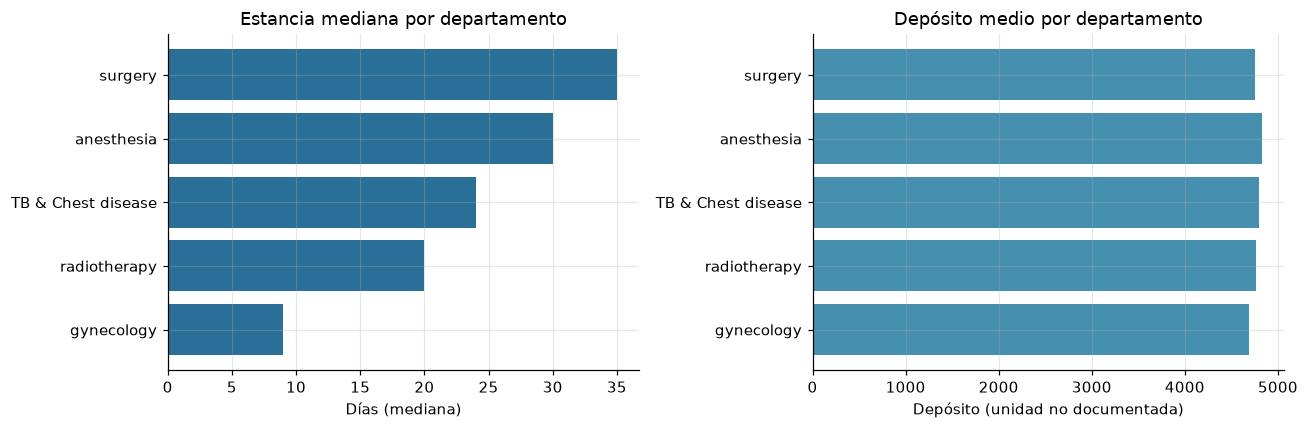

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d = tables["department"].sort_values("estancia_dias_mediana")
axes[0].barh(d["department"], d["estancia_dias_mediana"], color="#2a6f97")
axes[0].set(title="Estancia mediana por departamento", xlabel="Días (mediana)")
axes[1].barh(d["department"], d["deposito_admision_media"], color="#468faf")
axes[1].set(title="Depósito medio por departamento", xlabel="Depósito (unidad no documentada)")
plt.tight_layout(); plt.show()

### 7.2 Por severidad (pregunta 2)

In [16]:
tables["severity"]

,severity_of_illness,registros,estancia_dias_validos,estancia_dias_media,estancia_dias_mediana,estancia_dias_desv_est,estancia_dias_minimo,estancia_dias_maximo,deposito_admision_validos,deposito_admision_media,deposito_admision_mediana,deposito_admision_desv_est,deposito_admision_minimo,deposito_admision_maximo
0,Minor,131537,131537,11.45,9.0,6.97,3,51,131537,4749.10,4636.65,1058.42,1654.01,9813.47
1,Moderate,280197,280197,12.72,9.0,8.18,3,51,280197,4718.71,4621.39,1049.48,1715.80,10104.73
2,Extreme,88266,88266,12.69,9.0,8.25,3,50,88266,4693.85,4630.06,1022.66,1744.90,9897.66


### 7.3 Por disponibilidad de personal (pregunta 3)
Usa `staff_availability_group` con los umbrales de EA2 (Bajo 0-3, Medio 4-6, Alto 7+); no son niveles clínicos de suficiencia.

In [17]:
tables["staff_availability"]

,staff_availability_group,registros,estancia_dias_validos,estancia_dias_media,estancia_dias_mediana,estancia_dias_desv_est,estancia_dias_minimo,estancia_dias_maximo,deposito_admision_validos,deposito_admision_media,deposito_admision_mediana,deposito_admision_desv_est,deposito_admision_minimo,deposito_admision_maximo
0,Bajo (0-3),180291,180291,12.26,9.0,7.74,3,51,180291,4722.89,4625.05,1048.70,1654.01,9872.65
1,Medio (4-6),137125,137125,12.59,9.0,8.18,3,51,137125,4718.34,4626.81,1043.22,1690.92,9657.61
2,Alto (7+),182584,182584,12.35,9.0,7.88,3,50,182584,4724.74,4628.78,1049.04,1725.69,10104.73


### 7.4 Departamento × severidad (pregunta 4)

In [18]:
display(tables["department_severity"])
display(df.pivot_table(index="department", columns="severity_of_illness", values="stay_in_days", aggfunc="median", observed=True).rename_axis(columns="Mediana de estancia (días)"))

,department,severity_of_illness,registros,estancia_dias_validos,estancia_dias_media,estancia_dias_mediana,estancia_dias_desv_est,estancia_dias_minimo,estancia_dias_maximo,deposito_admision_validos,deposito_admision_media,deposito_admision_mediana,deposito_admision_desv_est,deposito_admision_minimo,deposito_admision_maximo
0,TB & Chest disease,Minor,5505,5505,20.83,24.0,8.42,6,38,5505,4813.84,4676.46,1085.19,2035.22,9342.01
1,TB & Chest disease,Moderate,13040,13040,21.42,25.0,8.70,4,41,13040,4818.37,4694.10,1069.58,1818.93,9473.51
2,TB & Chest disease,Extreme,4345,4345,20.72,24.0,8.34,5,39,4345,4721.10,4655.63,1052.32,2017.04,9124.35
3,anesthesia,Minor,9170,9170,26.65,29.0,8.30,10,51,9170,4832.50,4698.80,1069.00,1962.84,9351.26
4,anesthesia,Moderate,26487,26487,27.81,30.0,7.87,10,49,26487,4829.33,4694.30,1080.80,1715.80,10104.73
5,anesthesia,Extreme,8522,8522,27.64,30.0,8.24,9,49,8522,4806.90,4725.09,1038.28,1867.59,9418.81
6,gynecology,Minor,98393,98393,8.60,9.0,1.10,3,13,98393,4732.32,4619.27,1053.95,1654.01,9813.47
7,gynecology,Moderate,185472,185472,8.66,9.0,1.02,4,13,185472,4685.13,4591.33,1037.93,1725.69,9899.19
8,gynecology,Extreme,59613,59613,8.63,9.0,1.12,3,14,59613,4647.28,4591.78,1013.27,1744.90,9897.66
9,radiotherapy,Minor,17961,17961,15.94,20.0,8.34,4,32,17961,4775.69,4677.45,1068.42,1999.45,9616.62


Mediana de estancia (días),Minor,Moderate,Extreme
department,,,
TB & Chest disease,24.0,25.0,24.0
anesthesia,29.0,30.0,30.0
gynecology,9.0,9.0,9.0
radiotherapy,20.0,21.0,20.0
surgery,33.0,35.0,34.0


### 7.5 Rango de estancia (pregunta 5)
`pct_total` usa los 500.000 registros como denominador; `pct_clasificados`, solo los que recibieron rango.

In [19]:
display(tables["stay_range"])
display(pd.crosstab(df["severity_of_illness"], df["stay_range"], margins=True, margins_name="Total"))
display(pd.crosstab(df["department"], df["stay_range"], margins=True, margins_name="Total"))

,stay_range,registros,pct_total,pct_clasificados
0,Corta (1-3 días),18,0.00,0.00
1,Moderada (4-7 días),74934,14.99,14.99
2,Prolongada (>7 días),425048,85.01,85.01
3,Sin clasificar,0,0.00,NaN
4,Total,500000,100.00,NaN


stay_range,Corta (1-3 días),Moderada (4-7 días),Prolongada (>7 días),Total
severity_of_illness,,,,
Minor,2,20861,110674,131537
Moderate,8,40688,239501,280197
Extreme,8,13385,74873,88266
Total,18,74934,425048,500000


stay_range,Corta (1-3 días),Moderada (4-7 días),Prolongada (>7 días),Total
department,,,,
TB & Chest disease,0,297,22593,22890
anesthesia,0,0,44179,44179
gynecology,4,42704,300770,343478
radiotherapy,14,31933,52368,84315
surgery,0,0,5138,5138
Total,18,74934,425048,500000


### 7.6 Puntaje exploratorio de complejidad (pregunta 5)
Solo para registros con categorías de peso definido; **no** es un instrumento clínico ni un predictor.

In [20]:
tables["complexity"]

,clinical_complexity_score,registros,estancia_dias_validos,estancia_dias_media,estancia_dias_mediana,estancia_dias_desv_est,estancia_dias_minimo,estancia_dias_maximo,deposito_admision_validos,deposito_admision_media,deposito_admision_mediana,deposito_admision_desv_est,deposito_admision_minimo,deposito_admision_maximo
0,1.25,18187,18187,11.60,9.0,7.12,4,47,18187,4766.29,4614.80,1067.91,1654.01,9664.43
1,1.5,71625,71625,11.62,9.0,7.15,4,50,71625,4745.83,4642.00,1049.59,1690.92,9813.47
2,2.5,27140,27140,12.84,9.0,8.12,3,51,27140,4735.81,4585.89,1087.33,1789.17,9759.70
3,3,172851,172851,13.06,9.0,8.51,3,50,172851,4747.52,4638.11,1056.56,1715.80,10104.73
4,3.75,8353,8353,12.49,9.0,8.09,3,46,8353,4650.00,4553.20,1063.06,1971.50,9692.65
5,4.5,66060,66060,12.75,9.0,8.31,3,50,66060,4695.42,4638.04,1010.02,1744.90,9897.66
6,(sin dato),135784,135784,11.74,9.0,7.23,3,51,135784,4686.78,4613.78,1038.63,1710.21,9785.69


### 7.7 Indicadores derivados por departamento (pregunta 5)
`deposit_per_stay_day` y `visitors_per_day` son cocientes descriptivos; las unidades son depósito (no documentado) por día y visitantes por día.

In [21]:
tables["indicators"]

,department,registros,deposito_por_dia_validos,deposito_por_dia_media,deposito_por_dia_mediana,deposito_por_dia_desv_est,deposito_por_dia_minimo,deposito_por_dia_maximo,visitas_por_dia_validos,visitas_por_dia_media,visitas_por_dia_mediana,visitas_por_dia_desv_est,visitas_por_dia_minimo,visitas_por_dia_maximo
0,TB & Chest disease,22890,22890,281.34,213.56,161.31,67.15,1475.77,22890,0.25,0.17,0.29,0.00,4.57
1,anesthesia,44179,44179,193.38,168.04,78.86,52.21,760.86,44179,0.15,0.11,0.16,0.00,2.46
2,gynecology,343478,343478,552.79,528.87,146.34,176.11,2015.59,343478,0.41,0.38,0.22,0.00,2.60
3,radiotherapy,84315,84315,447.43,253.97,321.97,70.59,1933.53,84315,0.35,0.20,0.38,0.00,6.40
4,surgery,5138,5138,190.01,141.45,110.86,48.26,864.91,5138,0.14,0.10,0.14,0.02,2.29


### 7.8 Calidad de los datos

In [22]:
tables["data_quality"]

,variable,tipo_final,registros,nulos,pct_nulos,validos,observaciones
0,available_extra_rooms_in_hospital,int64,500000,0,0.00,500000,Sin observaciones
1,department,category,500000,0,0.00,500000,Sin observaciones
2,ward_facility_code,category,500000,0,0.00,500000,Sin observaciones
3,doctor_name,category,500000,0,0.00,500000,Sin observaciones
4,staff_available,int64,500000,0,0.00,500000,Sin observaciones
5,patientid,int64,500000,0,0.00,500000,"Identificador, no cuantitativo. Repetido en 37..."
6,age,category,500000,0,0.00,500000,Sin observaciones
7,gender,category,500000,0,0.00,500000,Sin observaciones
8,type_of_admission,category,500000,0,0.00,500000,Sin observaciones
9,severity_of_illness,category,500000,0,0.00,500000,Sin observaciones


### 7.9 Consistencia de las tablas

In [23]:
N = len(df)
assert tables["department"]["registros"].sum() == N
assert tables["severity"]["registros"].sum() == N
assert tables["staff_availability"]["registros"].sum() == N
assert tables["department_severity"]["registros"].sum() == N
sr = tables["stay_range"].set_index("stay_range")["registros"]
assert sr.drop("Total").sum() == N == sr["Total"]
assert tables["complexity"]["registros"].sum() == N
assert tables["indicators"]["registros"].sum() == N
for k in ("department", "severity", "staff_availability", "department_severity", "complexity"):
    t = tables[k]
    assert (t["estancia_dias_validos"] <= t["registros"]).all() and (t["deposito_admision_validos"] <= t["registros"]).all()
# Los promedios por grupo coinciden con un cálculo independiente
chk = df.groupby("department", observed=True)["stay_in_days"].mean().round(2)
assert (tables["department"].set_index("department")["estancia_dias_media"] == chk).all()
# Los CSV exportados coinciden con las tablas
for k, path in paths.items():
    pd.testing.assert_frame_equal(pd.read_csv(ROOT / path), tables[k], check_dtype=False, check_exact=False)
print("Conteos, denominadores y CSV de resultados consistentes.")

Conteos, denominadores y CSV de resultados consistentes.


## 8. Hallazgos descriptivos (generados desde las tablas)

In [24]:
findings = key_findings(tables)
display(Markdown("\n".join(f"* {f}" for f in findings)))

* Estancia mediana por departamento: de 9.0 días (gynecology, n=343478) a 35.0 días (surgery, n=5138).
* Depósito medio por departamento: de 4692.08 (gynecology) a 4825.66 (anesthesia) (unidad monetaria no documentada).
* Estancia media por severidad: Minor 11.45 d (n=131537); Moderate 12.72 d (n=280197); Extreme 12.69 d (n=88266).
* Depósito medio por severidad: Minor 4749.10; Moderate 4718.71; Extreme 4693.85.
* Estancia media por grupo de personal: Bajo (0-3) 12.26 d (n=180291); Medio (4-6) 12.59 d (n=137125); Alto (7+) 12.35 d (n=182584).
* Rangos de estancia (% sobre el total): Corta (1-3 días) 0.00 % (n=18); Moderada (4-7 días) 14.99 % (n=74934); Prolongada (>7 días) 85.01 % (n=425048); Sin clasificar 0.00 % (n=0).
* Depósito por día de estancia (mediana): de 141.45 (surgery) a 528.87 (gynecology); cociente descriptivo, no costo diario.
* Puntaje exploratorio de complejidad calculado para 364216 registros de 500000; el resto queda sin puntaje (categorías sin peso definido).

## 9. Interpretación

*(Las cifras citadas provienen de las tablas de la sección 7, calculadas con las 500.000 filas; los hallazgos de la sección 8 se generan por código.)*

**Pregunta 1 – Departamento.** Es el factor con mayores diferencias de estancia: la mediana va de 9 días en `gynecology` (343.478 registros, desviación 1,06) a 35 días en `surgery` (5.138 registros). El depósito medio varía poco entre departamentos (de 4.692,08 a 4.825,66). Esto describe los registros observados; no indica qué departamento es más o menos eficiente.

**Pregunta 2 – Severidad.** La mediana de estancia es de 9 días en las tres categorías y las medias difieren poco (11,45 en Minor; 12,72 en Moderate; 12,69 en Extreme). El depósito medio desciende levemente de Minor (4.749,10) a Extreme (4.693,85). En estos registros la severidad no se asocia con una diferencia grande de estancia ni de depósito, y no se interpreta como determinante de la duración.

**Pregunta 3 – Personal.** Las medias de estancia por grupo (12,26; 12,59 y 12,35 días) y de depósito (4.722,89; 4.718,34 y 4.724,74) son casi iguales. Con estos datos y estos umbrales no se observa un patrón por disponibilidad de personal; la definición de `staff_available` no está documentada.

**Pregunta 4 – Departamento × severidad.** Dentro de cada departamento la estancia media casi no cambia entre severidades (p. ej., gynecology: 8,60; 8,66; 8,63; surgery: 29,81; 31,08; 30,42). El depósito sí muestra sentidos distintos según el departamento (en gynecology baja de Minor a Extreme; en radiotherapy, Extreme es el más alto). Las diferencias entre departamentos se mantienen en las tres severidades. Son descripciones de grupos observados, sin control de otros factores.

**Pregunta 5 – Indicadores derivados.**
* `stay_range`: el 85,01 % de los registros es «Prolongada» (>7 días), el 14,99 % «Moderada» y solo 18 registros «Corta», porque la estancia mínima observada es de 3 días y la mediana de 9. Con estos umbrales la segmentación discrimina poco; convendría revisarlos con criterios de la institución.
* `clinical_complexity_score`: solo se calculó para 364.216 registros (72,84 %), porque la categoría `Emergency` (135.784 registros) no tiene peso definido en el mapeo propuesto y `Elective` no existe en los datos. Las medias de estancia por puntaje van de 11,60 a 13,06 días con medianas de 9 en todos los casos y sin orden monótono: es una exploración, no un predictor.
* `deposit_per_stay_day`, `visitors_per_day` y los benchmarks (`dept_avg_stay`, `stay_vs_dept_avg`, `dept_severity_avg_deposit`) permiten comparar registros con su grupo, pero no representan costo diario, carga asistencial ni ineficiencia.

**Hipótesis (no verificadas).** Las diferencias entre departamentos podrían reflejar cómo se registran o distribuyen los servicios, algo que estos datos no permiten confirmar.

**Limitaciones.** Ficha sin licencia, procedencia, periodo ni definiciones; análisis descriptivo sin causalidad; `admission_deposit` no es el costo total; `health_conditions` conserva 30,38 % de nulos sin imputar; `patientid` se repite y tiene valores negativos de significado desconocido; los umbrales de personal y de rango de estancia y los pesos del puntaje son reglas del proyecto, no criterios clínicos.


## 9. Exportación del dataset enriquecido (muestra)
Se exportan como máximo `CSV_MAX_ROWS` (100.000) filas, **las primeras en su orden original** (selección determinista, sin azar). Las tablas de la sección 7 **no** se calcularon con este archivo.

In [25]:
export = export_csv_head(df, config.ENRICHED_CSV)
display(pd.DataFrame([export]))
check = pd.read_csv(ROOT / export["archivo"])
assert check.shape == (export["filas_exportadas"], df.shape[1]) and len(check) <= config.CSV_MAX_ROWS
assert list(check.columns) == list(df.columns)
print(f"DataFrame completo: {len(df):,} filas | CSV exportado: {len(check):,} filas x {check.shape[1]} columnas | {export['tamano_mb']} MB | parcial: {export['es_parcial']}")
assert export["tamano_mb"] < 50, "El archivo supera el umbral de aviso de GitHub"

,archivo,filas_dataset_completo,filas_exportadas,es_parcial,tamano_mb
0,data/processed/healthcare_enriched_sample.csv,500000,100000,True,21.93


DataFrame completo: 500,000 filas | CSV exportado: 100,000 filas x 25 columnas | 21.93 MB | parcial: True


## 10. Reporte automático `reports/data-enrichment-summary.txt`
Se genera con `DatasetSummarizer` (el mismo de EA1) a partir del DataFrame final **completo**, con secciones adicionales calculadas en esta ejecución.

In [26]:
all_log = log + elog
calc_lines = [f"- {r['paso']}: {r['registros_calculados']} calculados de {r['filas_despues']} ({r['registros_calculados'] / r['filas_despues'] * 100:.2f} %)"
              for r in elog if "registros_calculados" in r]
invalid_lines = [
    f"- Errores de conversión numérica: {log[1]['valores_no_convertibles']}; valores negativos detectados (se conservan): {log[1]['valores_negativos_detectados']}",
    f"- Duplicados exactos eliminados: {log[2]['duplicados_eliminados']}",
    f"- Categorías de admisión sin peso en el puntaje: {r4['categorias_admision_sin_peso']}; severidad sin peso: {r4['categorias_severidad_sin_peso']}",
    f"- Categorías del mapeo ausentes en los datos: {r4['categorias_del_mapeo_ausentes_en_datos']}",
    f"- Divisiones omitidas por estancia inválida: {r1['denominadores_invalidos']} (depósito/día), {r2['denominadores_invalidos']} (visitas/día)",
    f"- Registros sin rango de estancia: {r3['sin_clasificar']}",
]
result_lines = [f"- {paths[k]}: {TABLE_QUESTIONS[k]} ({len(tables[k])} filas)" for k in tables]
extra = [
    ("Proyecto y alcance", ["Proyecto: Análisis Descriptivo de la Estancia Hospitalaria y Factores Operativos en Admisiones Médicas.",
                            "Actividad: AE3 - Transformación y Enriquecimiento de Datos. Escenario institucional HIPOTÉTICO.",
                            f"Registros cargados: {len(raw)} | analizados (DataFrame enriquecido completo): {len(df)} | exportados a CSV de muestra: {export['filas_exportadas']}"]),
    ("Fórmulas y reglas de los indicadores derivados", [f"- {r['paso']}: {r['descripcion']}" for r in elog]),
    ("Registros calculados por indicador", calc_lines),
    ("Categorías desconocidas y valores inválidos", invalid_lines),
    ("Tablas de resultados (calculadas con el DataFrame completo)", result_lines),
    ("Principales resultados descriptivos", [f"- {f}" for f in findings]),
    ("Limitaciones", [
        "- Análisis descriptivo: las diferencias entre grupos NO implican causalidad ni eficiencia clínica.",
        "- La ficha del dataset no documenta licencia, procedencia, carácter sintético/real, periodo ni definiciones de columnas.",
        "- admission_deposit no necesariamente es el costo del tratamiento; su unidad monetaria no está documentada.",
        "- deposit_per_stay_day y visitors_per_day son cocientes descriptivos, no costo diario ni carga asistencial.",
        "- clinical_complexity_score es una regla exploratoria del proyecto (no validada) y no se calcula para categorías sin peso definido.",
        "- Los umbrales de stay_range y staff_availability_group son convenciones del proyecto.",
        "- patientid no es único y tiene valores negativos de significado desconocido; no se usa como variable cuantitativa.",
        f"- El CSV {export['archivo']} contiene solo las primeras {export['filas_exportadas']} de {len(df)} filas.",
    ]),
]
ruta = DatasetSummarizer(title="RESUMEN AE3 - TRANSFORMACIÓN Y ENRIQUECIMIENTO DE DATOS (healthcare-hospital-stay-analytics)").save(
    df, config.ENRICHMENT_SUMMARY_TXT, dataset_info=info,
    transformations=tr.describe_log(all_log), exports=[export], extra_sections=extra)
txt = ruta.read_text(encoding="utf-8")
assert f"Filas: {len(df)}" in txt and f"Columnas: {df.shape[1]}" in txt and "clinical_complexity_score" in txt and "Split: train" in txt
print("Generado:", ruta.relative_to(ROOT).as_posix(), f"({len(txt.splitlines())} líneas, {ruta.stat().st_size} bytes)")
print(txt[:2500], "\n[...]")

Generado: reports/data-enrichment-summary.txt (181 líneas, 13235 bytes)
RESUMEN AE3 - TRANSFORMACIÓN Y ENRIQUECIMIENTO DE DATOS (healthcare-hospital-stay-analytics)
Fecha de generación: 2026-11-08 13:24:16 UTC-0500

Dataset: Nicolybgs/healthcare_data
Configuración: default
Split: train
Carga: dataset completo (sin muestreo)

Filas: 500000
Columnas: 25
Filas duplicadas: 0

Nombres de columnas:
available_extra_rooms_in_hospital, department, ward_facility_code, doctor_name, staff_available, patientid, age, gender, type_of_admission, severity_of_illness, health_conditions, visitors_with_patient, insurance, admission_deposit, stay_in_days, staff_availability_group, deposit_per_stay_day, visitors_per_day, stay_range, severity_weight, admission_type_weight, clinical_complexity_score, dept_avg_stay, stay_vs_dept_avg, dept_severity_avg_deposit

Tipos de datos:
- available_extra_rooms_in_hospital: int64
- department: category
- ward_facility_code: category
- doctor_name: category
- staff_availab

## 11. Conclusiones

* El dataset completo se transformó y enriqueció **sin eliminar registros**; las nueve variables derivadas se añadieron sin multiplicar filas y los nulos no se imputaron.
* Las tablas de `results/` responden las preguntas 1 a 5 con cifras calculadas sobre todos los registros; el CSV de muestra y el reporte TXT quedan en `data/processed/` y `reports/`.
* Las limitaciones (ficha sin documentación, indicadores exploratorios, ausencia de causalidad) se detallan en el reporte y en la sección de interpretación.